# Boston House Price Prediction — Part 1: Exploratory Data Analysis (EDA)

## Goal of the Project

The goal of this project is to predict house prices using housing and neighborhood characteristics.

Target Variable:
- medv (Median House Value)

In this notebook we will:

1. Data Overview
2. Data Cleaning
3. Univariate Analysis
4. Bivariate Analysis
5. Correlation Analysis
6. Outlier Detection
7. Key Findings

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings

warnings.filterwarnings("ignore")

sns.set_theme(
    style="whitegrid",
    palette="deep"
)

plt.rcParams["figure.figsize"] = (8,5)


## 2. Load the Data

In [2]:
df=pd.read_csv("boston_data.csv")

### Column Description

1. ID – Record identifier.

2. indus – Proportion of industrial land.

3. chas – Charles River dummy variable.

4. nox – Nitric oxide concentration.

5. rm – Average number of rooms.

6. age – Percentage of old houses.

7. dis – Distance to employment centers.

8. rad – Highway accessibility index.

9. tax – Property tax rate.

10. ptratio – Student teacher ratio.

11. lstat – Lower status population percentage.

12. medv – Median house value (Target Variable).

#### 3. Basic Data Inspection


In [5]:
print(
    "Shape:",
    df.shape
)

Shape: (333, 12)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 12 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   ID       333 non-null    int64  
 1   indus    333 non-null    float64
 2   chas     333 non-null    int64  
 3   nox      333 non-null    float64
 4   rm       333 non-null    float64
 5   age      333 non-null    float64
 6   dis      333 non-null    float64
 7   rad      333 non-null    int64  
 8   tax      333 non-null    int64  
 9   ptratio  333 non-null    float64
 10  lstat    333 non-null    float64
 11  medv     333 non-null    float64
dtypes: float64(8), int64(4)
memory usage: 31.3 KB


In [7]:
df.describe()

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
count,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000
mean,250.951952,11.293483,0.060060,0.557144,6.265619,68.226426,3.709934,9.633634,409.279279,18.448048,12.515435,22.768769
std,147.859438,6.998123,0.237956,0.114955,0.703952,28.133344,1.981123,8.742174,170.841988,2.151821,7.067781,9.173468
min,1.000000,0.740000,0.000000,0.385000,3.561000,6.000000,1.129600,1.000000,188.000000,12.600000,1.730000,5.000000
25%,123.000000,5.130000,0.000000,0.453000,5.884000,45.400000,2.122400,4.000000,279.000000,17.400000,7.180000,17.400000
50%,244.000000,9.900000,0.000000,0.538000,6.202000,76.700000,3.092300,5.000000,330.000000,19.000000,10.970000,21.600000
75%,377.000000,18.100000,0.000000,0.631000,6.595000,93.800000,5.116700,24.000000,666.000000,20.200000,16.420000,25.000000
max,506.000000,27.740000,1.000000,0.871000,8.725000,100.000000,10.710300,24.000000,711.000000,21.200000,37.970000,50.000000


In [8]:
print(
    "Missing Values:\n"
)

print(
    df.isnull().sum()
)

Missing Values:

ID         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
lstat      0
medv       0
dtype: int64


In [10]:
print(
    "Duplicate Rows:",
    df.duplicated().sum()
)

Duplicate Rows: 0


#### Observations

- Dataset structure has been inspected successfully.
- Missing values and duplicate records were checked.
- Initial statistical summary provides insight into feature distributions.

### 4: Data Cleaning
Kaunsi columns useful hain?

Kaunsi columns ko modeling me use karna hai?

Target variable kaunsa hai?

In [12]:
df.head()

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,4,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
3,5,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
4,7,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43,22.9


##### ID Column Drop
* The `ID` column is only a record identifier and does not provide any information about house prices.

* Therefore, it is removed before further analysis.

In [14]:
df = df.drop(columns=["ID"])

##### Define Target Variable
medv

In [15]:
target = "medv"

#### Numerical Columns
* Histogram
* Correlation
* Outlier Analysis

In [16]:
num_cols = df.columns.drop(target)


In [17]:
print(num_cols)

Index(['indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio',
       'lstat'],
      dtype='object')


In [18]:
df.head()

,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
3,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
4,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43,22.9


### Observations

- The `ID` column was removed because it is only a record identifier and has no predictive value.

- The target variable was defined as `medv`, which represents the median house value.

- All remaining columns are numerical features and will be used for exploratory data analysis and model development.

### Step 5: Target Variable Analysis

###### 5. Target Variable Analysis

Before analyzing the input features, it is important to understand the target variable (`medv`).

This helps us understand:

- The distribution of house prices
- Potential skewness
- Presence of outliers
- Overall price range in the dataset

#### Histogram + KDE Plot
* Histogram -House prices ka distribution dikhata hai. (Most houses kis price range me hain?
Distribution normal hai ya skewed?)
* Boxplot-Outliers identify karna.


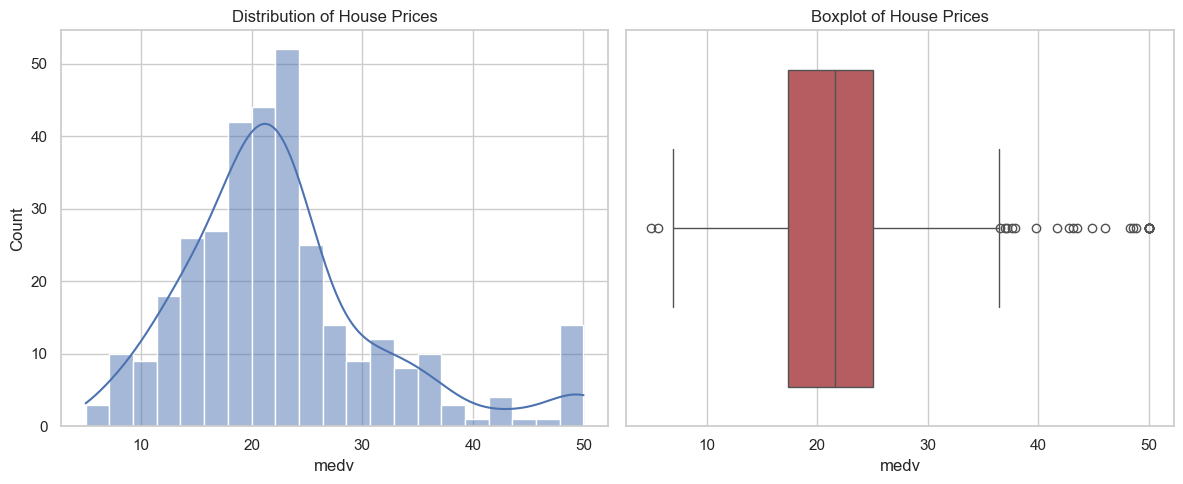

In [20]:

fig, ax = plt.subplots(1, 2, figsize=(12,5))

sns.histplot(
    data=df,
    x="medv",
    kde=True,
    color="#4c72b0",
    ax=ax[0]
)

ax[0].set_title("Distribution of House Prices")

sns.boxplot(
    x=df["medv"],
    color="#c44e52",
    ax=ax[1]
)

ax[1].set_title("Boxplot of House Prices")

plt.tight_layout()

plt.show()

In [24]:
kde=True #Distribution ko smooth form me dikhana.

In [26]:
print(
    "Skewness:",  #Distribution kis direction me tilted hai.
    round(
        df["medv"].skew(),
        2
    )
)

Skewness: 1.12


### Rules
 0     = Normal Distribution

+ve   = Right Skewed

-ve   = Left Skewed

###### Additional Statistics

In [27]:
print(
    df["medv"].describe()
)

count    333.000000
mean      22.768769
std        9.173468
min        5.000000
25%       17.400000
50%       21.600000
75%       25.000000
max       50.000000
Name: medv, dtype: float64


#### Observation


- The target variable `medv` represents the median house value.

- Most houses are concentrated within the mid-price range.

- The distribution appears slightly skewed, indicating some variation in house prices.

- A few high-priced houses may be present as outliers.

- The boxplot confirms the presence of some extreme observations on the higher end of the distribution.

- Understanding the target variable is important before building predictive models.

### Step 6: Univariate Analysis
* Ek time par ek feature ko analyze karna.
* Feature kaisa distributed hai?

 Normal hai?

 Skewed hai?

Outliers dikh rahe hain?

Data spread kaisa hai?


#### 6. Univariate Analysis

In this section, each feature is analyzed individually to understand its distribution, spread and potential outliers.

This helps us understand the characteristics of housing features before examining their relationship with house prices.

#### 6.1 Distribution of Numerical Features

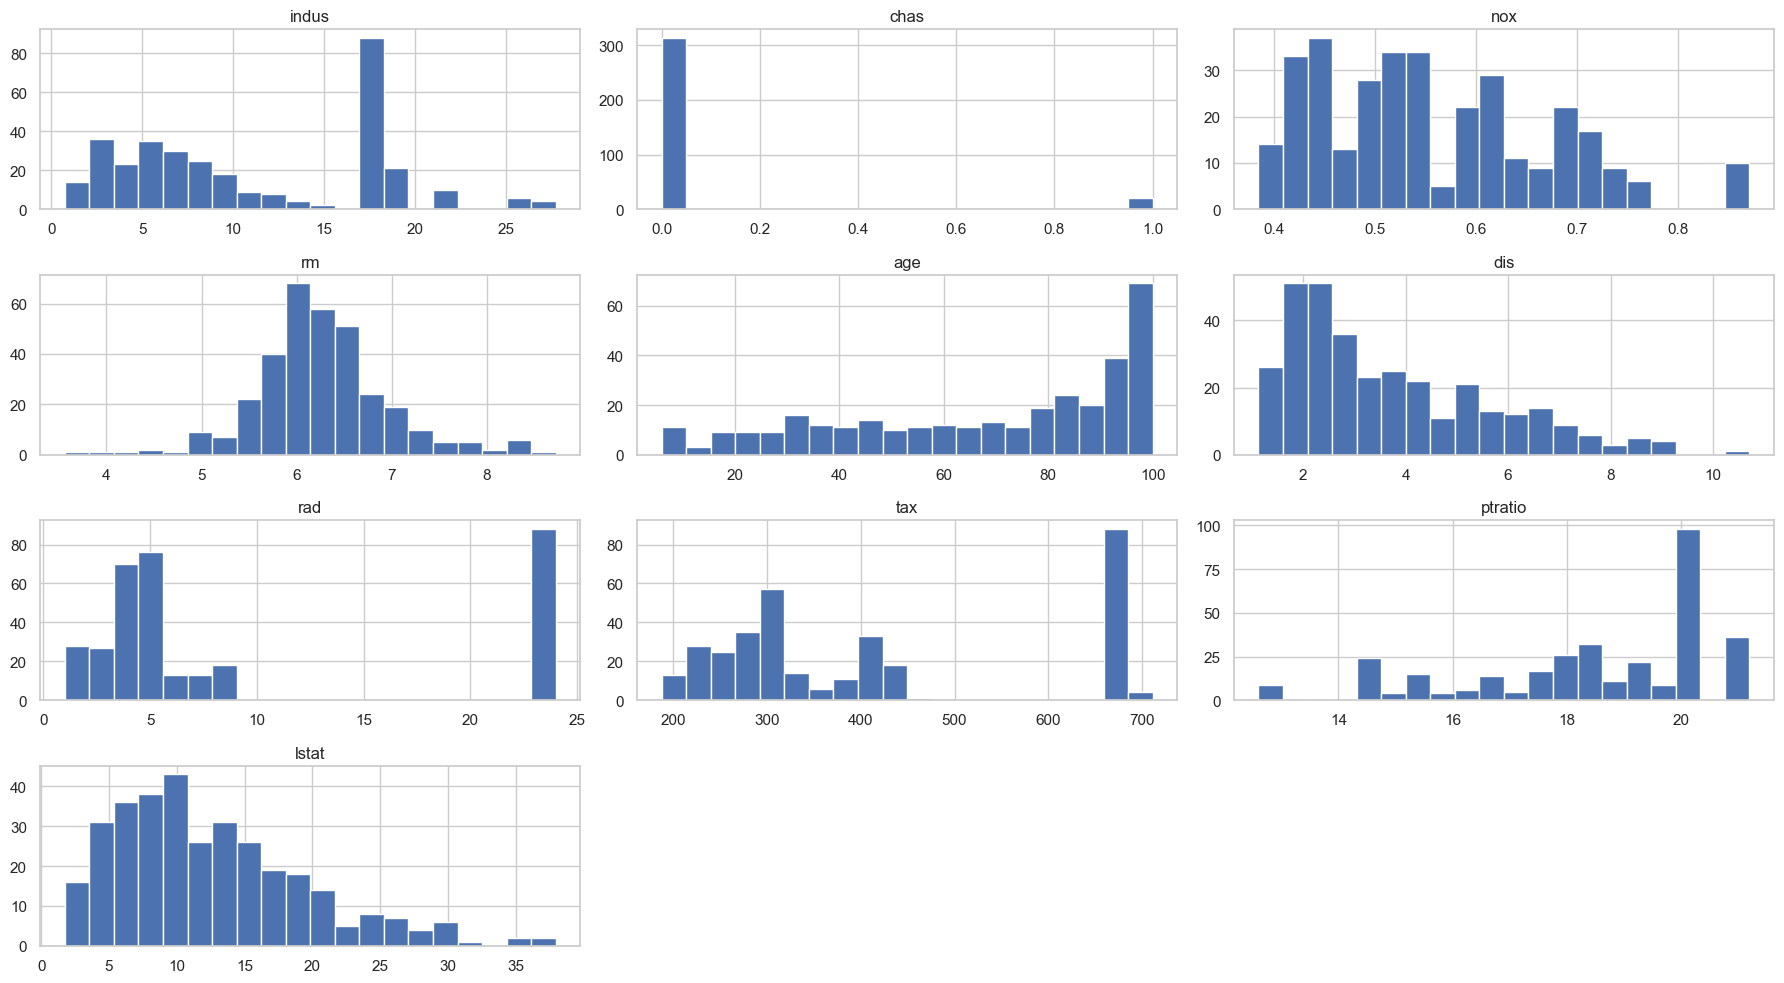

In [29]:
df[num_cols].hist(
    figsize=(18,10),
    bins=20,
    layout=(4,3),
    color="#4c72b0"
)

plt.tight_layout()

plt.show()

###### Histogram
Most values kaha concentrate hain?

Feature normal hai ya skewed?

Data spread kaisa hai?


In [30]:

print("Skewness of Numerical Features:\n")

print(
    df[num_cols]
    .skew()
    .round(2)
)

Skewness of Numerical Features:

indus      0.29
chas       3.72
nox        0.71
rm         0.28
age       -0.60
dis        0.94
rad        0.98
tax        0.63
ptratio   -0.79
lstat      0.98
dtype: float64


##### Observations

#### rm (Average Number of Rooms)

- Most houses contain between 5 and 7 rooms.
- The distribution appears reasonably close to normal.

#### lstat (Lower Status Population %)

- Positively skewed distribution.
- Most neighborhoods have lower percentages, while high values occur less frequently.

#### age

- Many neighborhoods contain a high proportion of older housing units.

#### tax

- Property tax rates vary considerably across neighborhoods.
- Some observations have substantially higher tax values.

#### rad

- Highway accessibility differs significantly across locations.
- Certain areas have much higher accessibility than others.

#### nox

- Pollution levels are concentrated around moderate values.
- Extreme pollution levels

## Step 7: Bivariate Analysis - What is related to House Price?
 7. Bivariate Analysis

In this section, we analyze the relationship between individual features and the target variable (`medv`).

The goal is to identify which features have the strongest impact on house prices.

#### 7.1 Numerical Features vs House Price

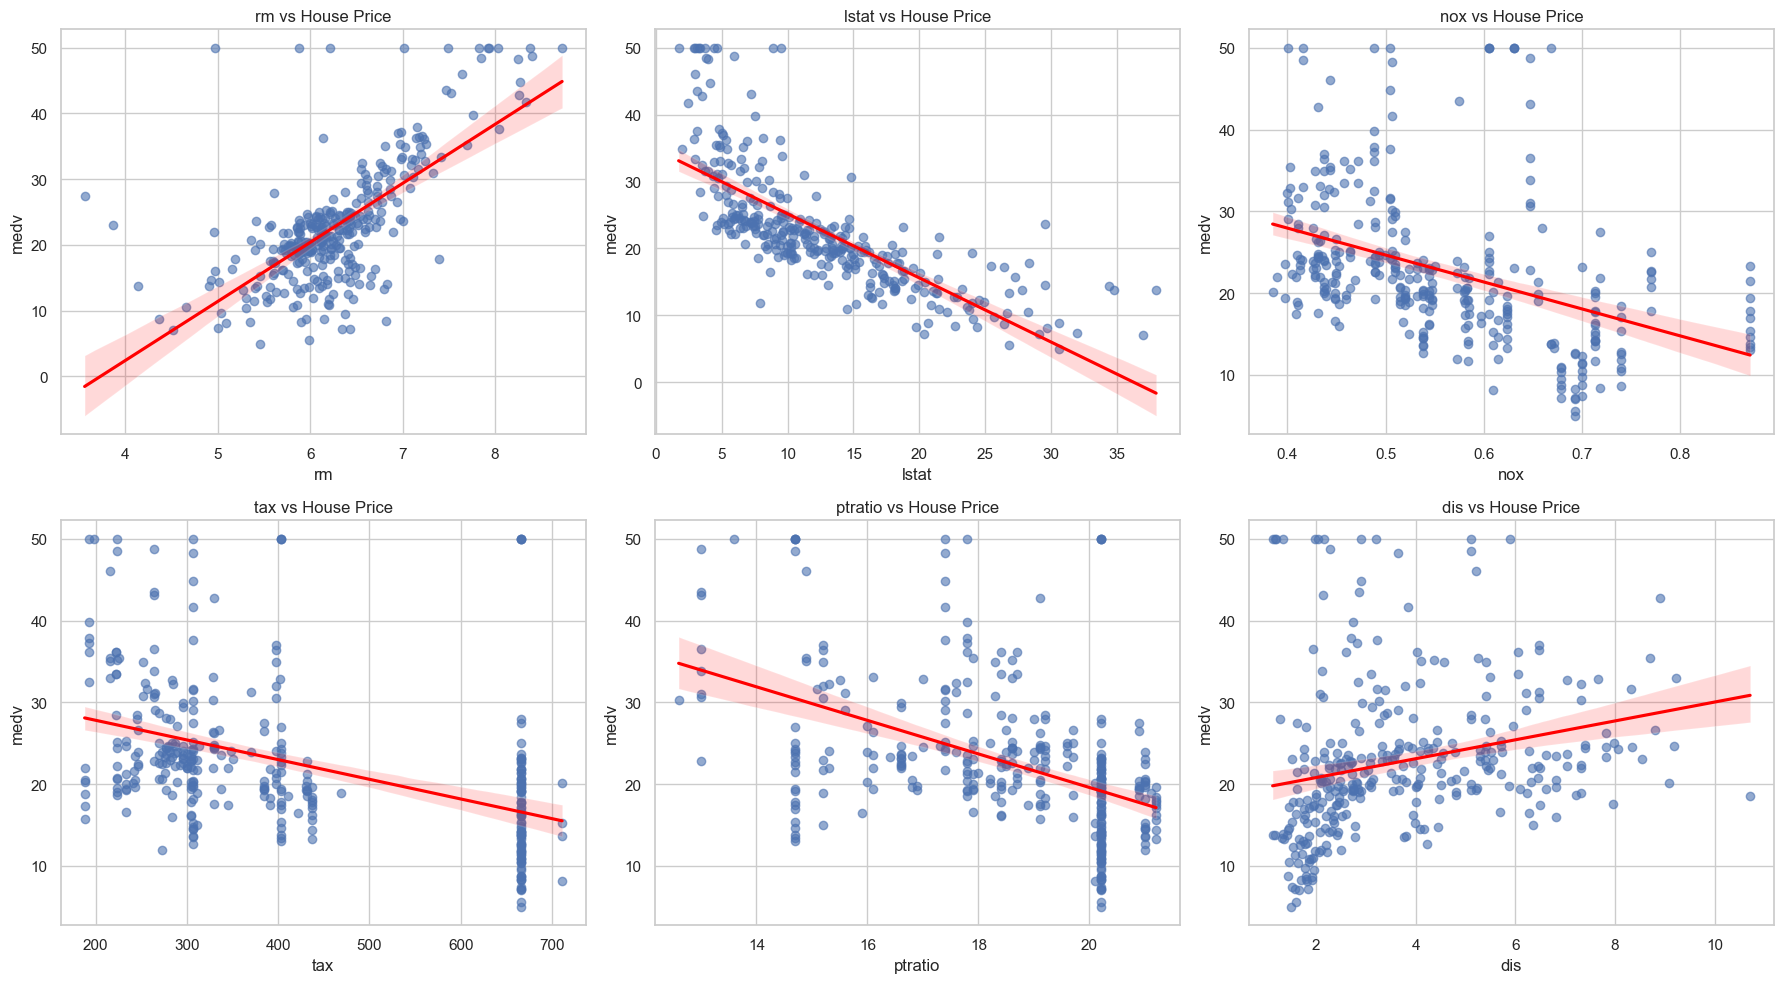

In [33]:
important_features = [
    "rm",
    "lstat",
    "nox",
    "tax",
    "ptratio",
    "dis"
]

fig, axes = plt.subplots(2, 3, figsize=(18,10))

for ax, col in zip(axes.ravel(), important_features):

    sns.regplot(   #Feature aur House Price ke beech relationship.
        data=df,
        x=col,
        y="medv",
        scatter_kws={"alpha":0.6},
        line_kws={"color":"red"},
        ax=ax
    )

    ax.set_title(f"{col} vs House Price")

plt.tight_layout()
plt.show()

#Red line:Red line:

### 7.2 Correlation with Target

In [34]:
corr_target = (
    df.corr()["medv"]
    .drop("medv")
    .sort_values(
        key=abs,
        ascending=False
    )
)

print(corr_target)

lstat     -0.738600
rm         0.689598
ptratio   -0.481376
indus     -0.473932
tax       -0.448078
nox       -0.413054
age       -0.358888
rad       -0.352251
dis        0.249422
chas       0.204390
Name: medv, dtype: float64


### Observations

#### RM (Average Rooms)

- Strong positive relationship with house prices.
- Houses with more rooms tend to have higher prices.

#### LSTAT

- Strong negative relationship.
- Areas with higher lower-status population percentages generally have lower house prices.

#### NOX

- Negative relationship with house prices.
- Higher pollution levels are associated with lower-valued homes.

#### PTRATIO

- Areas with high student-teacher ratios tend to have lower house prices.

#### TAX

- Higher property taxes are generally associated with lower property values.

#### DIS

- Distance from employment centers shows a weaker relationship.

#### 7.3 House Price by Room Groups
* Room count ko categories me divide karke dekhte hain.

In [36]:
room_bins = [0, 5, 6, 7, 10]

room_labels = [
    "Less than 5",
    "5-6",
    "6-7",
    "More than 7"
]

df["Room_Group"] = pd.cut(
    df["rm"],
    bins=room_bins,
    labels=room_labels
)

In [37]:
room_price = df.groupby(
    "Room_Group"
)["medv"].agg(
    ["count","mean"]
)

print(room_price.round(2))

             count   mean
Room_Group               
Less than 5     12  17.88
5-6            100  17.81
6-7            180  22.15
More than 7     41  39.03


### Visualization

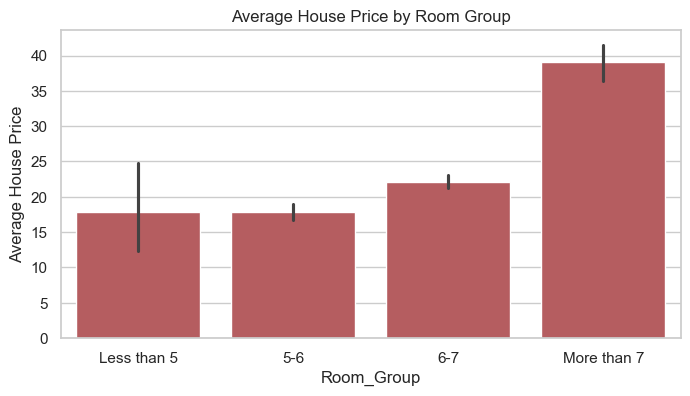

In [38]:
plt.figure(figsize=(8,4))

sns.barplot(
    data=df,
    x="Room_Group",
    y="medv",
    color="#c44e52"
)

plt.title("Average House Price by Room Group")

plt.ylabel("Average House Price")

plt.show()

#### Observation

- Houses with more rooms have significantly higher prices.

- Properties with more than 7 rooms belong to the highest-priced category.

- Smaller houses tend to have lower market values.

### 7.4 Pollution Level vs House Price    

In [39]:
df["Pollution_Level"] = pd.qcut(
    df["nox"],
    q=3,
    labels=["Low","Medium","High"]
)

In [40]:
pollution_price = df.groupby(
    "Pollution_Level"
)["medv"].mean()

print(
    pollution_price.round(2)
)

Pollution_Level
Low       27.17
Medium    22.75
High      17.87
Name: medv, dtype: float64


In [41]:
pollution_price = df.groupby(
    "Pollution_Level"
)["medv"].mean()

print(
    pollution_price.round(2)
)

Pollution_Level
Low       27.17
Medium    22.75
High      17.87
Name: medv, dtype: float64


### Observation

- Low-pollution areas have the highest average house prices.

- High-pollution areas tend to have lower property values.

- Environmental quality appears to play an important role in housing demand.

#### Final Observations
    

- RM is the strongest positive driver of house prices.

- LSTAT is the strongest negative driver.

- Pollution (NOX) negatively impacts house prices.

- Higher property taxes and higher student-teacher ratios are generally associated with lower property values.

- Houses with more rooms tend to be substantially more expensive.

- Environmental and neighborhood characteristics have a significant impact on house prices.

#### Step 8: Correlation Analysis
* Kaunsi features ek dusre se related hain?

* Kaunsi feature house price (medv) ke saath sabse strongly related hai?

* Multicollinearity ka issue hai ya nahi?

### 8. Correlation Analysis

Correlation measures the strength and direction of the relationship between variables.

A correlation value can range between:

- +1 → Perfect Positive Correlation
- 0 → No Correlation
- -1 → Perfect Negative Correlation

This analysis helps identify important predictors of house prices.

#### Correlation Matrix

In [43]:
corr = df.select_dtypes(include=np.number).corr()

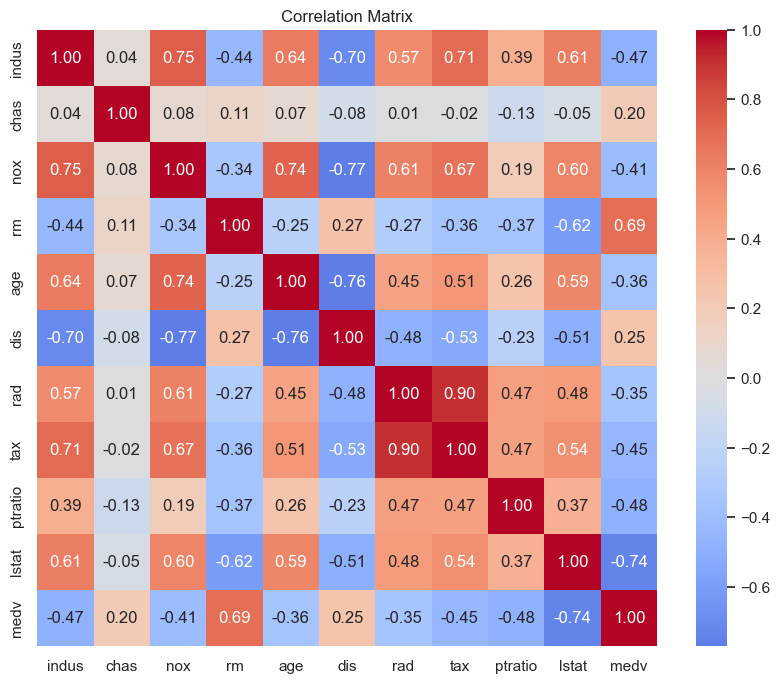

In [45]:
plt.figure(figsize=(10,8))

sns.heatmap(  # Feature vs Feature

#    Feature vs Target
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")

plt.show()

##### Correlation with House Price

In [48]:
print("Correlation with House Price:\n")

print(
    corr["medv"]
    .drop("medv")
    .sort_values(
        key=abs,
        ascending=False
    )
    .round(3)
)

# ke saath correlation dekhne ke liye.
# Sabse important feature kaunsi hai.


Correlation with House Price:

lstat     -0.739
rm         0.690
ptratio   -0.481
indus     -0.474
tax       -0.448
nox       -0.413
age       -0.359
rad       -0.352
dis        0.249
chas       0.204
Name: medv, dtype: float64


#### Observations

#### Strong Positive Correlation

- RM (average number of rooms) shows the strongest positive correlation with house prices.
- Houses with more rooms generally have higher market values.

#### Strong Negative Correlation

- LSTAT has the strongest negative relationship with house prices.
- Neighborhoods with higher lower-status population percentages tend to have lower-valued houses.

#### Other Important Variables

- PTRATIO shows a moderate negative relationship with house prices.
- TAX is negatively associated with property values.
- NOX (pollution) also negatively impacts house prices.

#### Weak Relationships

- DIS and AGE exhibit relatively weaker relationships with the target variable.

#### Multicollinearity

- No severe multicollinearity is observed among most features.
- The dataset appears suitable for regression modeling.

#### Business Insight

House size (`rm`) and neighborhood quality (`lstat`) appear to be the strongest drivers of property prices.

Environmental and social factors such as pollution levels, taxation and educational quality also influence housing values.

#### step 8 Final Conclusion
Strongest Positive Feature  → RM

Strongest Negative Feature  → LSTAT

Other Important Features    → PTRATIO, TAX, NOX

Weak Features              → AGE, DIS

9.1 Outlier Detection Using IQR
* IQR = Q3 - Q1  --Lower Bound = Q1 - 1.5 × IQR

* Upper Bound = Q3 + 1.5 × IQR

  

#### 9.2 Boxplots
Minimum Value

Maximum Value

Median

Outliers

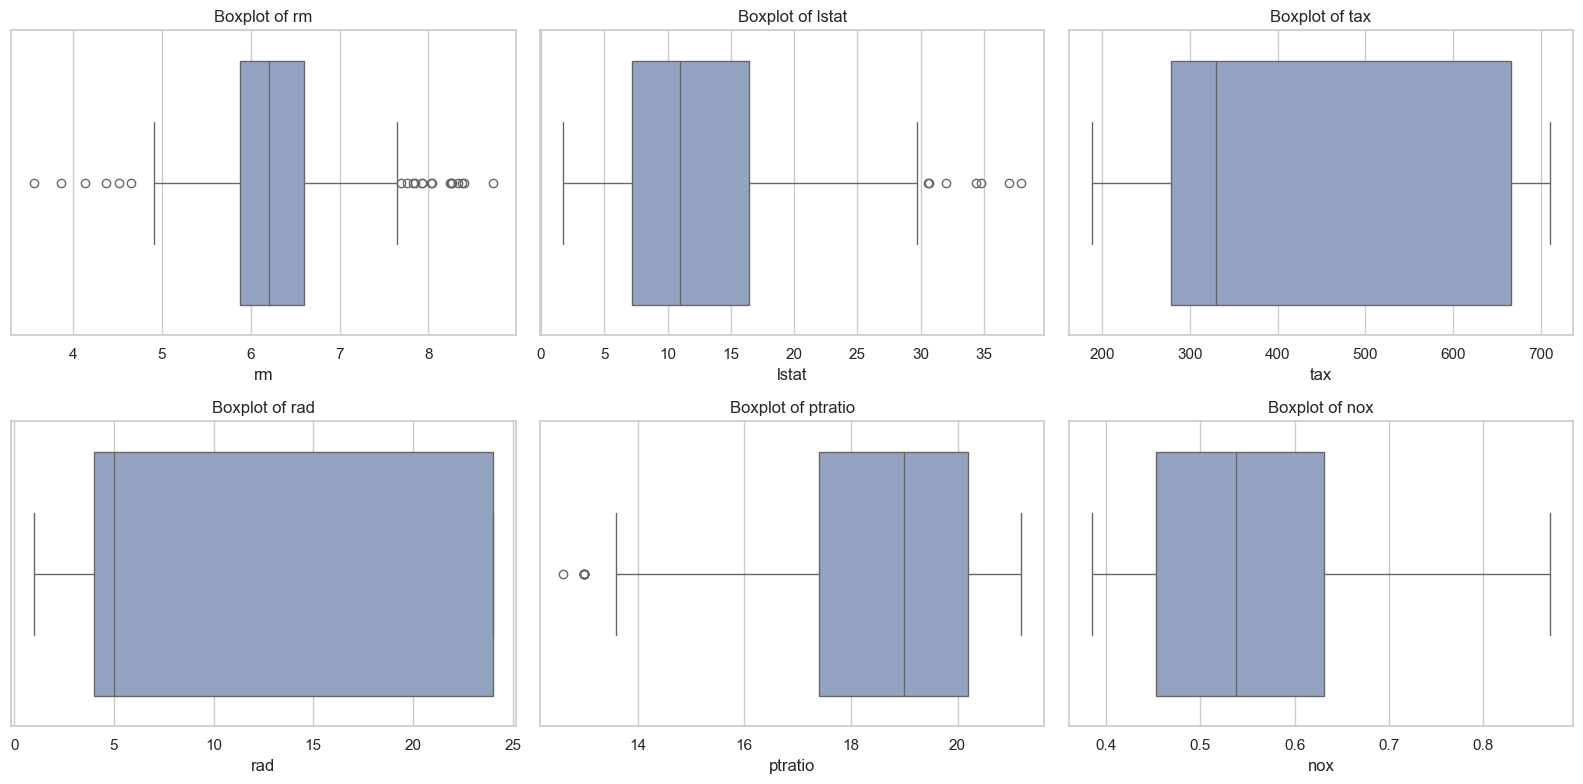

In [50]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(16,8)
)

cols = [
    "rm",
    "lstat",
    "tax",
    "rad",
    "ptratio",
    "nox"
]

for ax, col in zip(
    axes.ravel(),
    cols
):

    sns.boxplot(
        x=df[col],
        ax=ax,
        color="#8da0cb"
    )

    ax.set_title(
        f"Boxplot of {col}"
    )

plt.tight_layout()

plt.show()

##### Observations

- Several features contain outliers according to the IQR method.

- RAD shows a noticeable number of extreme values.

- TAX contains some unusually high observations.

- LSTAT includes several high-value observations.

- RM contains a few houses with exceptionally large numbers of rooms.

- These observations appear to represent real housing characteristics rather than data-entry errors.

#### Final Decision

###### Outlier Treatment Decision

Although several outliers are present, they appear to be genuine observations rather than data quality issues.

Therefore, these observations will be retained for further analysis and model development.

Tree-based models such as Random Forest and AdaBoost are generally robust to outliers, making removal unnecessary at this stage.

### Step 10: Summary of Key Findings

 10. Summary of Key Findings

##### Key Findings

1. The dataset contains housing and neighborhood-related characteristics that can be used to predict house prices.

2. The target variable is `medv` (Median House Value), making this a regression problem.

3. The dataset is clean, with no major data quality issues identified during inspection.

4. `rm` (average number of rooms) shows the strongest positive relationship with house prices.
   - Houses with more rooms generally have higher market values.

5. `lstat` (lower-status population percentage) shows the strongest negative relationship with house prices.
   - Areas with higher `lstat` values tend to have lower house prices.

6. Environmental factors influence property values:
   - Higher pollution levels (`nox`) are associated with lower house prices.
   - Cleaner neighborhoods generally command higher property values.

7. Neighborhood characteristics such as:
   - Property tax (`tax`)
   - Student-teacher ratio (`ptratio`)
   
   also show negative relationships with house prices.

8. Correlation analysis confirms that:
   - `rm`
   - `lstat`
   - `nox`
   - `tax`
   - `ptratio`
   
   are among the most important predictors of house prices.

9. Several outliers were detected in variables such as:
   - `rad`
   - `tax`
   - `lstat`
   - `rm`

   However, these observations appear to represent genuine housing conditions and will be retained.

10. No severe multicollinearity issues were observed among the features, making the dataset suitable for regression modeling.